# Exercise: Dengue forecasting

Data: [DrivenData dengue benchmark](https://drivendata.co/blog/dengue-benchmark/)

## Setup

In [10]:
library('tidymodels')
library('slider')

## Load the data

In [11]:
dengue = readr::read_csv('../data/dengue_features_train.csv', show_col_types = FALSE)
labels = readr::read_csv('../data/dengue_labels_train.csv', show_col_types = FALSE)

dengue |> glimpse()

Rows: 1,456
Columns: 24
$ city                                  <chr> "sj", "sj", "sj", "sj", "sj", "s…
$ year                                  <dbl> 1990, 1990, 1990, 1990, 1990, 19…
$ weekofyear                            <dbl> 18, 19, 20, 21, 22, 23, 24, 25, …
$ week_start_date                       <date> 1990-04-30, 1990-05-07, 1990-05…
$ ndvi_ne                               <dbl> 0.1226000, 0.1699000, 0.0322500,…
$ ndvi_nw                               <dbl> 0.10372500, 0.14217500, 0.172966…
$ ndvi_se                               <dbl> 0.1984833, 0.1623571, 0.1572000,…
$ ndvi_sw                               <dbl> 0.1776167, 0.1554857, 0.1708429,…
$ precipitation_amt_mm                  <dbl> 12.42, 22.82, 34.54, 15.36, 7.52…
$ reanalysis_air_temp_k                 <dbl> 297.5729, 298.2114, 298.7814, 29…
$ reanalysis_avg_temp_k                 <dbl> 297.7429, 298.4429, 298.8786, 29…
$ reanalysis_dew_point_temp_k           <dbl> 292.4143, 293.9514, 295.4343, 29…
$ reanalysis_max

## 1. Count the missing values

<details>
<summary>Hint</summary>

```R
dengue |>
    summarize(across(everything(), \(x) sum(is.na(x)))) |>
    pivot_longer(everything(), names_to = 'column', values_to = 'n_missing') |>
    arrange(desc(n_missing))
```

</details>

In [12]:
dengue |>
    summarize(across(everything(), \(x) sum(is.na(x)))) |>
    pivot_longer(everything(), names_to = 'column', values_to = 'n_missing') |>
    arrange(desc(n_missing))

   column                                n_missing
1  ndvi_ne                               194      
2  ndvi_nw                                52      
3  station_avg_temp_c                     43      
4  station_diur_temp_rng_c                43      
5  ndvi_se                                22      
6  ndvi_sw                                22      
7  station_precip_mm                      22      
8  station_max_temp_c                     20      
9  station_min_temp_c                     14      
10 precipitation_amt_mm                   13      
11 reanalysis_sat_precip_amt_mm           13      
12 reanalysis_air_temp_k                  10      
13 reanalysis_avg_temp_k                  10      
14 reanalysis_dew_point_temp_k            10      
15 reanalysis_max_air_temp_k              10      
16 reanalysis_min_air_temp_k              10      
17 reanalysis_precip_amt_kg_per_m2        10      
18 reanalysis_relative_humidity_percent   10      
19 reanalysis_specific_humidity

## 2. Fill the missing values

Sort by date. Fill each city on its own. Keep 4 features. Join the labels.

<details>
<summary>Hint</summary>

```R
preprocess_data = function(features, labels = NULL) {
    keep = c(
        'city', 'year', 'weekofyear', 'week_start_date',
        'reanalysis_specific_humidity_g_per_kg',
        'reanalysis_dew_point_temp_k',
        'station_avg_temp_c',
        'station_min_temp_c'
    )
    df = features |>
        select(all_of(keep)) |>
        arrange(city, week_start_date) |>
        group_by(city) |>
        fill(everything(), .direction = 'down') |>
        ungroup()
    if (!is.null(labels)) {
        df = df |> left_join(labels, by = c('city', 'year', 'weekofyear'))
    }
    df
}

dengue_processed = preprocess_data(dengue, labels)

dengue_processed |> summarize(across(everything(), \(x) sum(is.na(x))))
```

</details>

In [14]:
preprocess_data = function(features, labels = NULL) {
    keep = c(
        'city', 'year', 'weekofyear', 'week_start_date',
        'reanalysis_specific_humidity_g_per_kg',
        'reanalysis_dew_point_temp_k',
        'station_avg_temp_c',
        'station_min_temp_c'
    )
    df = features |>
        select(all_of(keep)) |>
        arrange(city, week_start_date) |>
        group_by(city) |>
        fill(everything(), .direction = 'down') |>
        ungroup()
    if (!is.null(labels)) {
        df = df |> left_join(labels, by = c('city', 'year', 'weekofyear'))
    }
    df
}

dengue_processed = preprocess_data(dengue, labels)

dengue_processed |> summarize(across(everything(), \(x) sum(is.na(x))))

  city year weekofyear week_start_date reanalysis_specific_humidity_g_per_kg
1 0    0    0          0               0                                    
  reanalysis_dew_point_temp_k station_avg_temp_c station_min_temp_c total_cases
1 0                           0                  0                  0          

## 3. Train and test sets, by city

<details>
<summary>Hint</summary>

```R
dengue_sj = dengue_processed |> filter(city == 'sj')
dengue_iq = dengue_processed |> filter(city == 'iq')

sj_train = dengue_sj |> slice(1:800)
sj_test = dengue_sj |> slice(801:n())

iq_train = dengue_iq |> slice(1:400)
iq_test = dengue_iq |> slice(401:n())
```

</details>

In [15]:
dengue_sj = dengue_processed |> filter(city == 'sj')
dengue_iq = dengue_processed |> filter(city == 'iq')

sj_train = dengue_sj |> slice(1:800)
sj_test = dengue_sj |> slice(801:n())

iq_train = dengue_iq |> slice(1:400)
iq_test = dengue_iq |> slice(401:n())

## 4. Random forest, one model per city

<details>
<summary>Hint</summary>

```R
mod = rand_forest(trees = 500, min_n = 30) |> set_mode('regression')

formula = total_cases ~ weekofyear + reanalysis_specific_humidity_g_per_kg +
    reanalysis_dew_point_temp_k + station_avg_temp_c + station_min_temp_c

mod_sj_fit = mod |> fit(formula, data = sj_train)

mod_iq_fit = mod |> fit(formula, data = iq_train)
```

</details>

In [16]:
mod = rand_forest(trees = 500, min_n = 30) |> set_mode('regression')

formula = total_cases ~ weekofyear + reanalysis_specific_humidity_g_per_kg +
    reanalysis_dew_point_temp_k + station_avg_temp_c + station_min_temp_c

mod_sj_fit = mod |> fit(formula, data = sj_train)

mod_iq_fit = mod |> fit(formula, data = iq_train)

## 5. Plot the test predictions

<details>
<summary>Hint</summary>

```R
options(repr.plot.width = 10, repr.plot.height = 4, repr.plot.res = 250)

sj_test |>
    mutate(fitted = predict(mod_sj_fit, new_data = sj_test)$.pred, t = row_number()) |>
ggplot(aes(x = t)) +
    geom_line(aes(y = total_cases, color = 'actual')) +
    geom_line(aes(y = fitted, color = 'predicted')) +
    labs(x = 'week', y = 'total_cases', color = NULL) +
    theme_minimal()
```

</details>

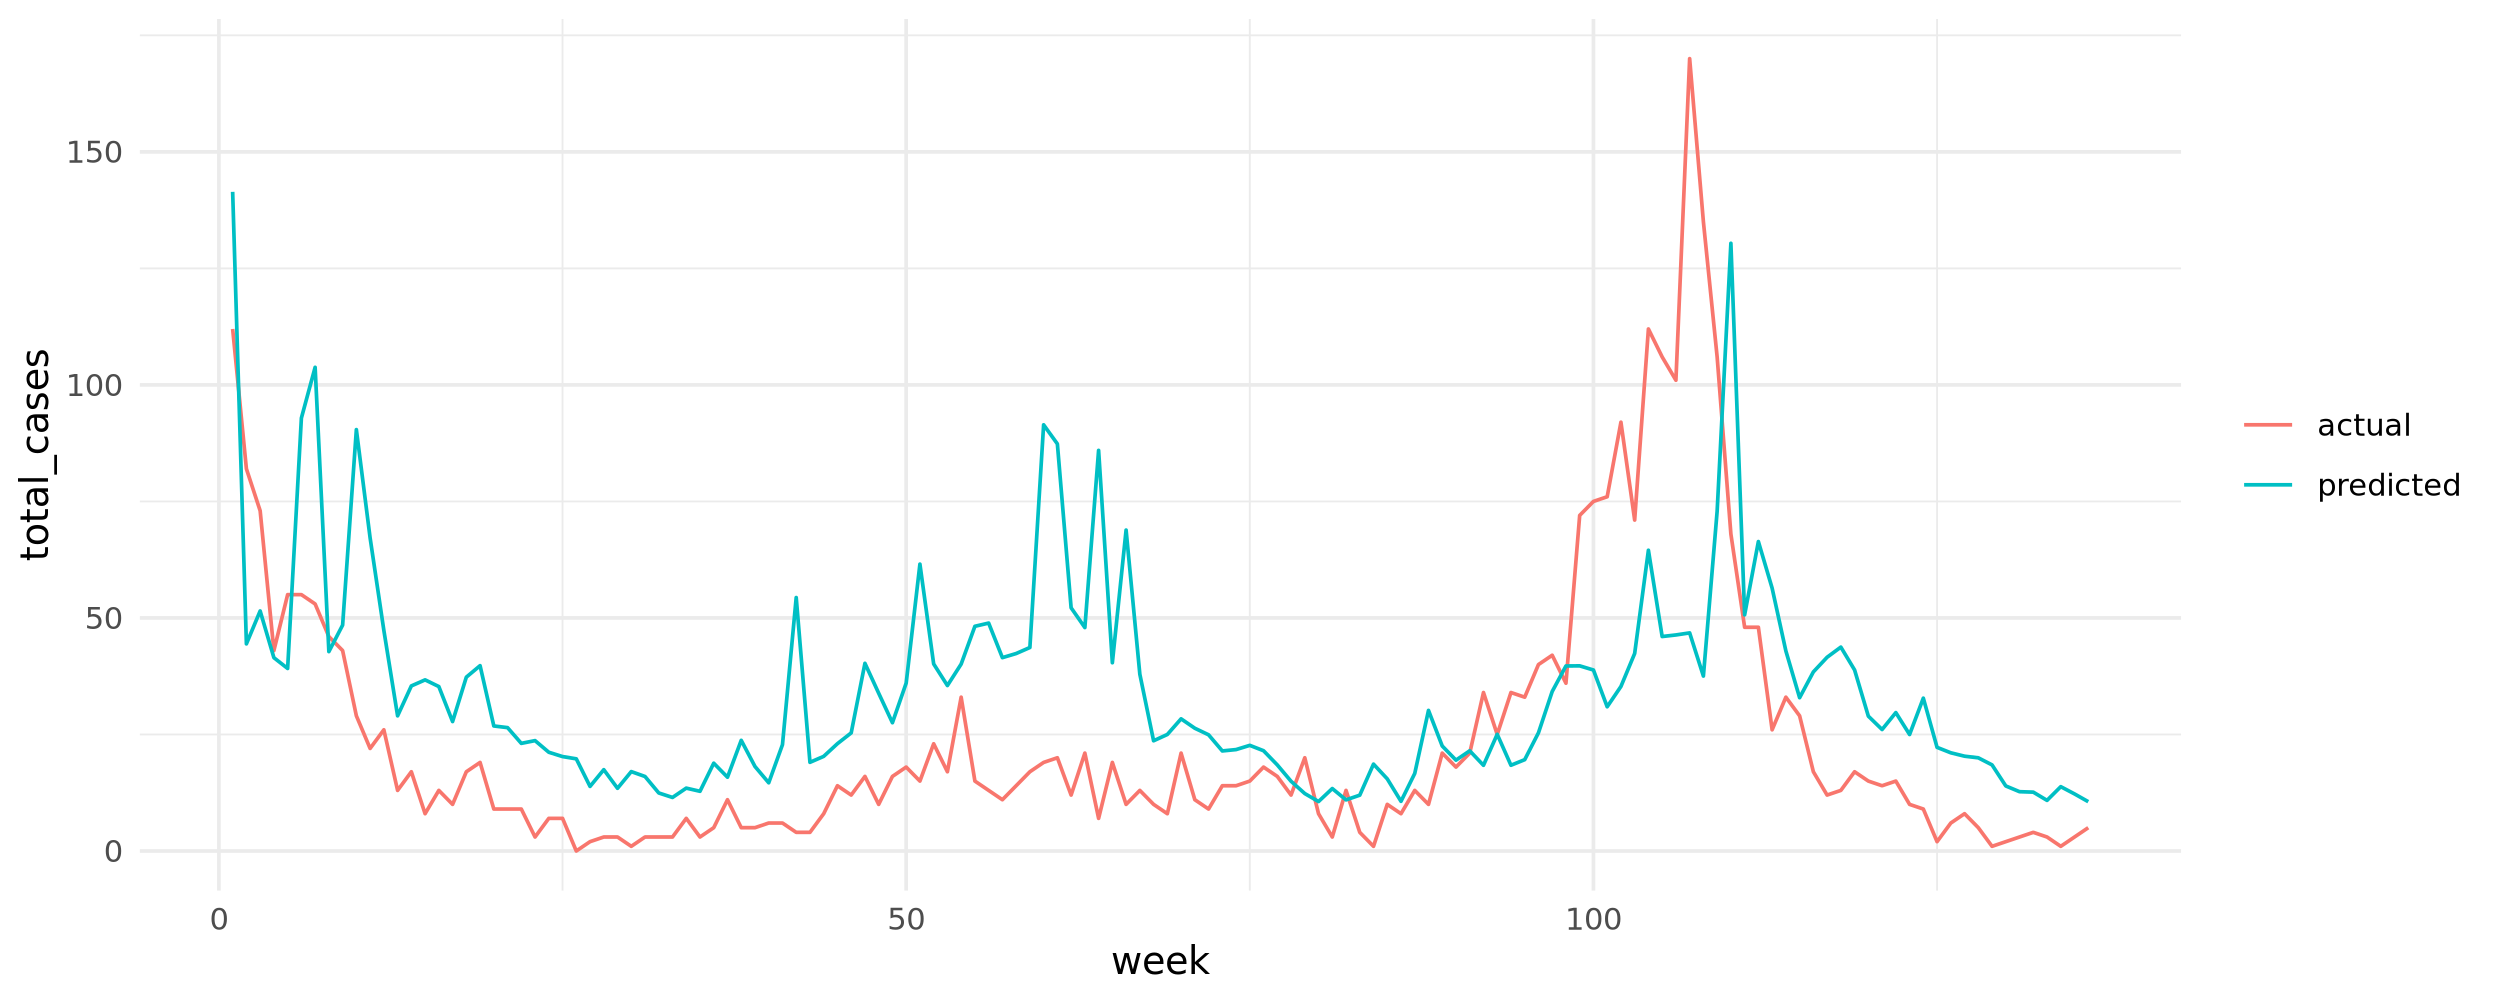

In [17]:
options(repr.plot.width = 10, repr.plot.height = 4, repr.plot.res = 250)

sj_test |>
    mutate(fitted = predict(mod_sj_fit, new_data = sj_test)$.pred, t = row_number()) |>
ggplot(aes(x = t)) +
    geom_line(aes(y = total_cases, color = 'actual')) +
    geom_line(aes(y = fitted, color = 'predicted')) +
    labs(x = 'week', y = 'total_cases', color = NULL) +
    theme_minimal()

## 6. Lag features

Build these per city:

- Rolling means (2, 4, 6, 8 weeks) of humidity, dew point, min temp, air temp, precipitation
- Cases at t-1, t-2, t-4, and rolling means (4, 8 weeks) of cases up to t-1
- `week_sin` and `week_cos`

<details>
<summary>Hint</summary>

```R
# Mean of the last w weeks (this week and the w - 1 before it)
# .complete = TRUE gives NA for the first w - 1 weeks, which have too few weeks
roll_mean = function(x, w) slider::slide_dbl(x, mean, .before = w - 1, .complete = TRUE)

lag_data = dengue |>
    select(
        city, year, weekofyear, week_start_date,
        humidity = reanalysis_specific_humidity_g_per_kg,
        dew_point = reanalysis_dew_point_temp_k,
        min_temp = station_min_temp_c,
        air_temp = reanalysis_air_temp_k,
        precip = precipitation_amt_mm
    ) |>
    left_join(labels, by = c('city', 'year', 'weekofyear')) |>
    arrange(city, week_start_date) |>
    group_by(city) |>
    fill(everything(), .direction = 'down') |>
    mutate(
        across(
            c(humidity, dew_point, min_temp, air_temp, precip),
            list(
                ma2 = ~roll_mean(.x, 2),
                ma4 = ~roll_mean(.x, 4),
                ma6 = ~roll_mean(.x, 6),
                ma8 = ~roll_mean(.x, 8)
            ),
            .names = '{.col}_{.fn}'
        ),
        cases_lag1 = lag(total_cases, 1),
        cases_lag2 = lag(total_cases, 2),
        cases_lag4 = lag(total_cases, 4),
        cases_ma4 = roll_mean(lag(total_cases, 1), 4),
        cases_ma8 = roll_mean(lag(total_cases, 1), 8),
        week_sin = sin(2 * pi * weekofyear / 52),
        week_cos = cos(2 * pi * weekofyear / 52)
    ) |>
    ungroup() |>
    drop_na() |>
    # Keep only what the model uses: the rolling means, case lags and season
    select(-c(year, week_start_date, humidity, dew_point, min_temp, air_temp, precip))
```

</details>

In [18]:
roll_mean = function(x, w) slider::slide_dbl(x, mean, .before = w - 1, .complete = TRUE)

lag_data = dengue |>
    select(
        city, year, weekofyear, week_start_date,
        humidity = reanalysis_specific_humidity_g_per_kg,
        dew_point = reanalysis_dew_point_temp_k,
        min_temp = station_min_temp_c,
        air_temp = reanalysis_air_temp_k,
        precip = precipitation_amt_mm
    ) |>
    left_join(labels, by = c('city', 'year', 'weekofyear')) |>
    arrange(city, week_start_date) |>
    group_by(city) |>
    fill(everything(), .direction = 'down') |>
    mutate(
        across(
            c(humidity, dew_point, min_temp, air_temp, precip),
            list(
                ma2 = ~roll_mean(.x, 2),
                ma4 = ~roll_mean(.x, 4),
                ma6 = ~roll_mean(.x, 6),
                ma8 = ~roll_mean(.x, 8)
            ),
            .names = '{.col}_{.fn}'
        ),
        cases_lag1 = lag(total_cases, 1),
        cases_lag2 = lag(total_cases, 2),
        cases_lag4 = lag(total_cases, 4),
        cases_ma4 = roll_mean(lag(total_cases, 1), 4),
        cases_ma8 = roll_mean(lag(total_cases, 1), 8),
        week_sin = sin(2 * pi * weekofyear / 52),
        week_cos = cos(2 * pi * weekofyear / 52)
    ) |>
    ungroup() |>
    drop_na() |>
    # Keep only what the model uses: the rolling means, case lags and season
    select(-c(year, week_start_date, humidity, dew_point, min_temp, air_temp, precip))

## 7. Train and test sets for the lag features

Use the same test size as before.

<details>
<summary>Hint</summary>

```R
split_city = function(city_name, n_test) {
    d = lag_data |> filter(city == city_name) |> select(-city)
    list(
        train = d |> slice(1:(n() - n_test)),
        test = d |> slice((n() - n_test + 1):n())
    )
}

sj_lag_split = split_city('sj', nrow(sj_test))
iq_lag_split = split_city('iq', nrow(iq_test))
```

</details>

In [19]:
split_city = function(city_name, n_test) {
    d = lag_data |> filter(city == city_name) |> select(-city)
    list(
        train = d |> slice(1:(n() - n_test)),
        test = d |> slice((n() - n_test + 1):n())
    )
}

sj_lag_split = split_city('sj', nrow(sj_test))
iq_lag_split = split_city('iq', nrow(iq_test))

## 8. Random forest with lag features

<details>
<summary>Hint</summary>

```R
# `total_cases ~ .` uses every other column in the data
mod_sj_lag_fit = mod |> fit(total_cases ~ ., data = sj_lag_split$train)

mod_iq_lag_fit = mod |> fit(total_cases ~ ., data = iq_lag_split$train)
```

</details>

In [20]:
mod_sj_lag_fit = mod |> fit(total_cases ~ ., data = sj_lag_split$train)

mod_iq_lag_fit = mod |> fit(total_cases ~ ., data = iq_lag_split$train)

## 9. Compare the test error (MAE)

<details>
<summary>Hint</summary>

```R
mae = function(fit, test) mean(abs(predict(fit, new_data = test)$.pred - test$total_cases))

tibble(
    city = c('sj', 'iq'),
    baseline = c(mae(mod_sj_fit, sj_test), mae(mod_iq_fit, iq_test)),
    lag_features = c(mae(mod_sj_lag_fit, sj_lag_split$test), mae(mod_iq_lag_fit, iq_lag_split$test))
)
```

</details>

In [21]:
mae = function(fit, test) mean(abs(predict(fit, new_data = test)$.pred - test$total_cases))

tibble(
    city = c('sj', 'iq'),
    baseline = c(mae(mod_sj_fit, sj_test), mae(mod_iq_fit, iq_test)),
    lag_features = c(mae(mod_sj_lag_fit, sj_lag_split$test), mae(mod_iq_lag_fit, iq_lag_split$test))
)


  city baseline  lag_features
1 sj   21.383413 10.074216   
2 iq    6.552595  5.306125   

## 10. Plot the comparison

<details>
<summary>Hint</summary>

```R
plot_compare = function(fit_base, test_base, fit_lag, test_lag, title) {
    tibble(
        t = seq_len(nrow(test_lag)),
        actual = test_lag$total_cases,
        baseline = predict(fit_base, new_data = test_base)$.pred,
        lag_features = predict(fit_lag, new_data = test_lag)$.pred
    ) |>
        pivot_longer(-t) |>
        ggplot(aes(t, value, color = name)) +
        geom_line() +
        labs(title = title, x = 'week', y = 'total_cases', color = NULL) +
        theme_minimal()
}

plot_compare(mod_sj_fit, sj_test, mod_sj_lag_fit, sj_lag_split$test, 'San Juan')
plot_compare(mod_iq_fit, iq_test, mod_iq_lag_fit, iq_lag_split$test, 'Iquitos')
```

</details>

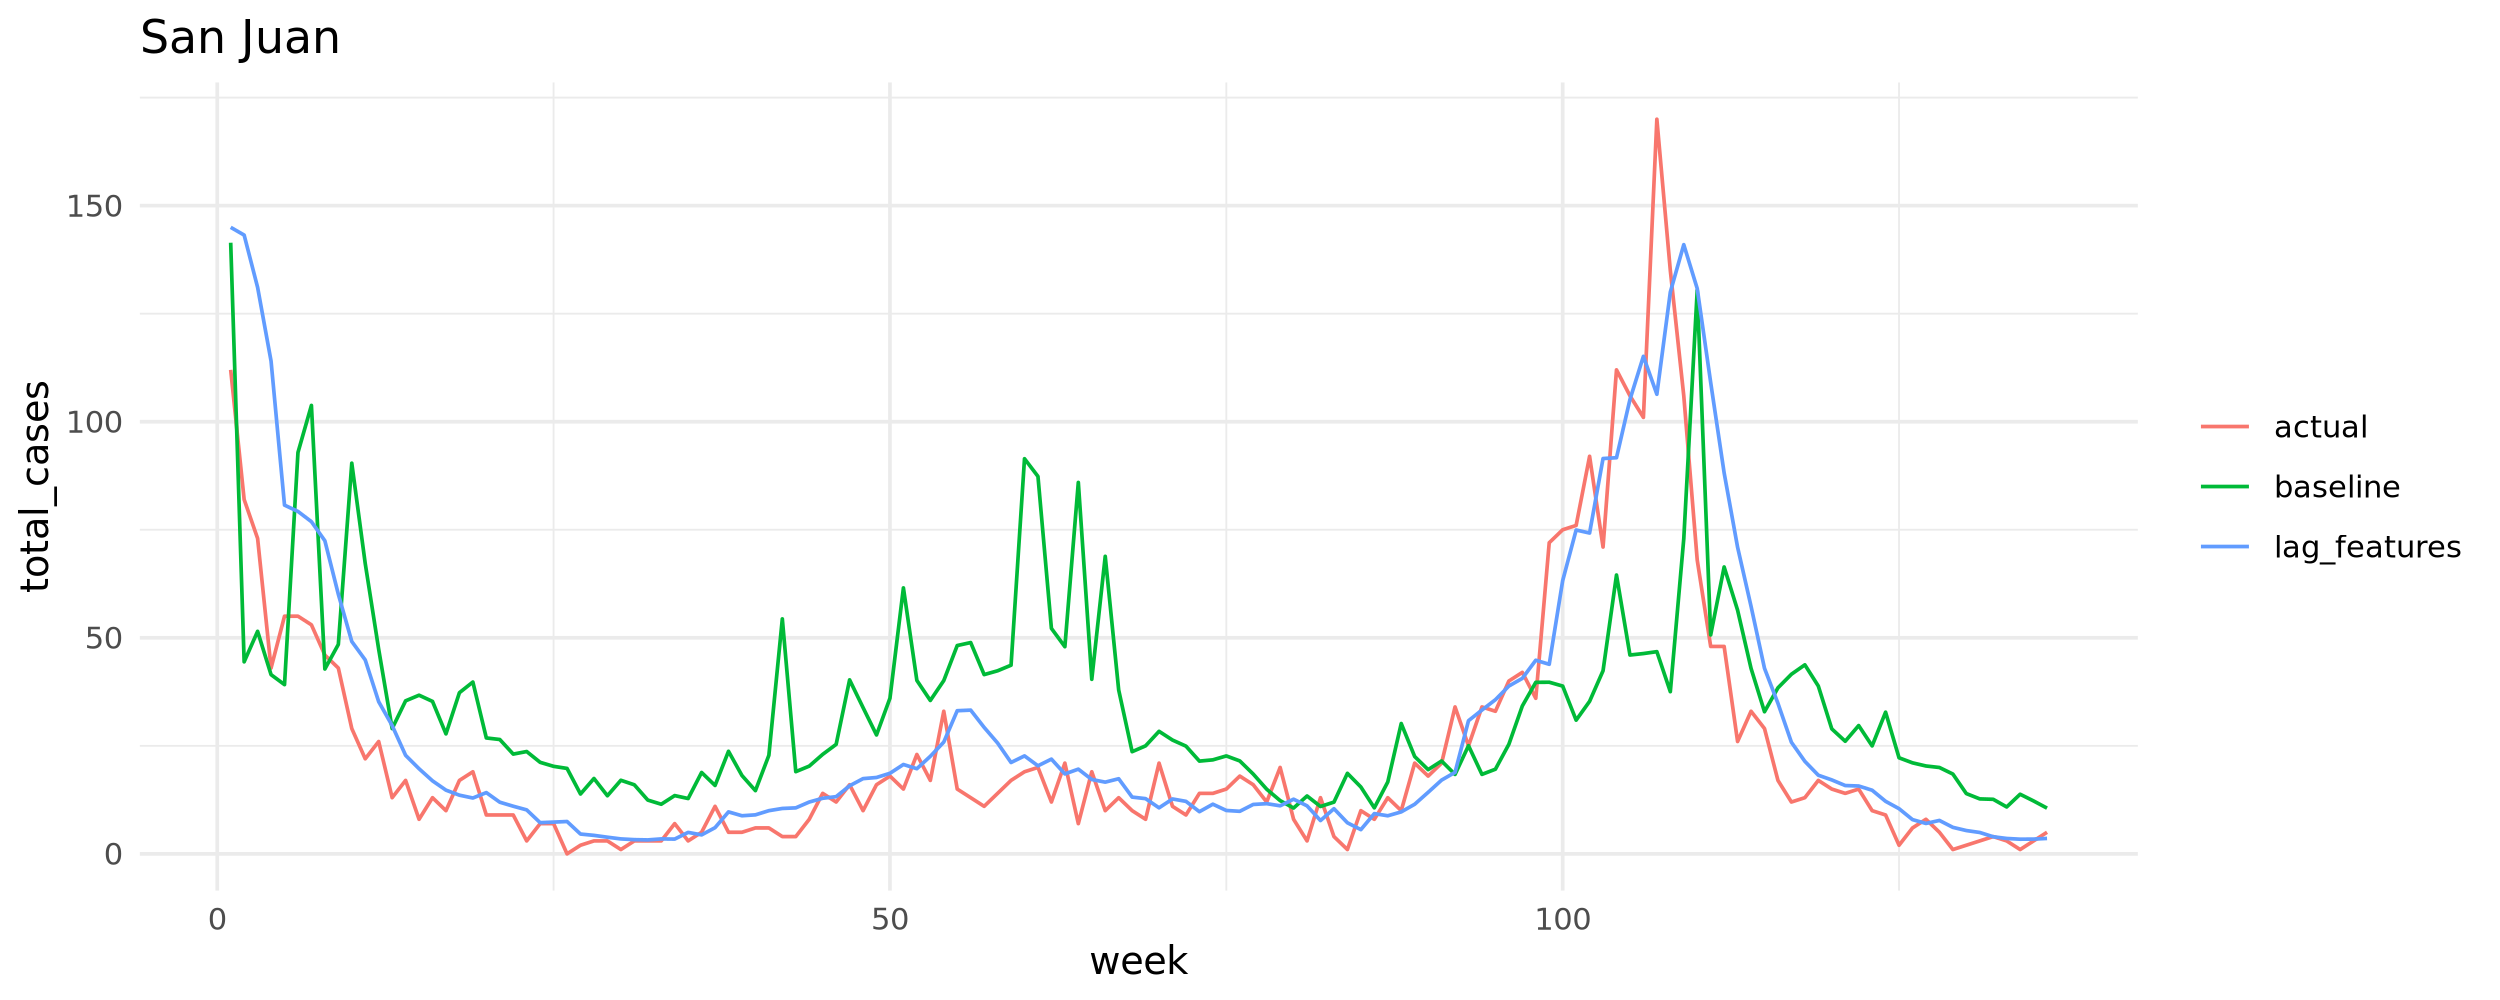

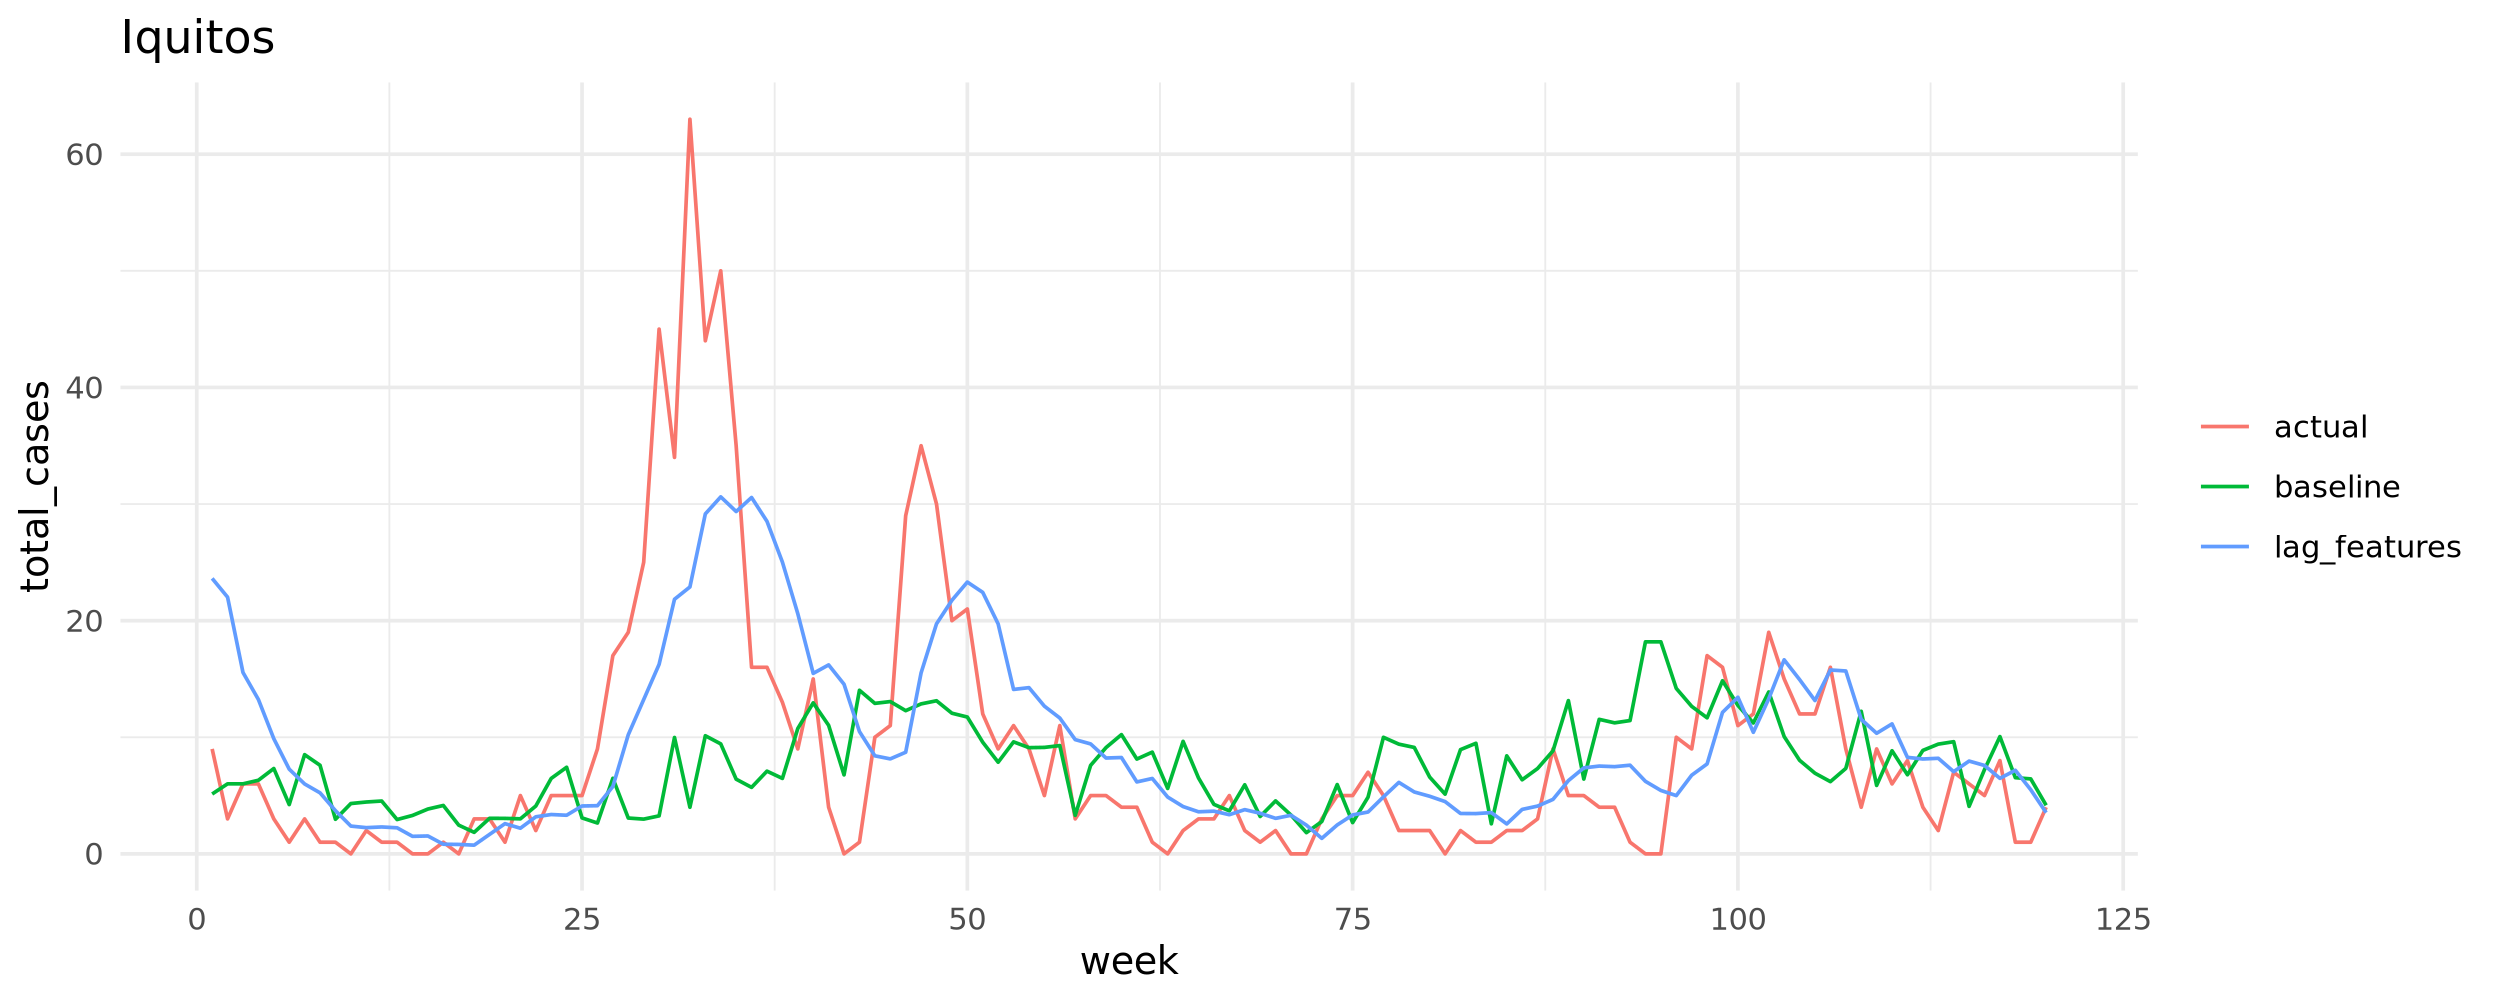

In [22]:
plot_compare = function(fit_base, test_base, fit_lag, test_lag, title) {
    tibble(
        t = seq_len(nrow(test_lag)),
        actual = test_lag$total_cases,
        baseline = predict(fit_base, new_data = test_base)$.pred,
        lag_features = predict(fit_lag, new_data = test_lag)$.pred
    ) |>
        pivot_longer(-t) |>
        ggplot(aes(t, value, color = name)) +
        geom_line() +
        labs(title = title, x = 'week', y = 'total_cases', color = NULL) +
        theme_minimal()
}

plot_compare(mod_sj_fit, sj_test, mod_sj_lag_fit, sj_lag_split$test, 'San Juan')
plot_compare(mod_iq_fit, iq_test, mod_iq_lag_fit, iq_lag_split$test, 'Iquitos')

## Bonus: variable importance

Make a `vip` chart of the San Juan model with lag features. Which columns matter most?

<details>
<summary>Hint</summary>

```R
# importance = 'impurity' tells ranger to keep track of importance
mod_imp = mod |> set_engine('ranger', importance = 'impurity')

mod_sj_imp_fit = mod_imp |> fit(total_cases ~ ., data = sj_lag_split$train)

vip::vip(mod_sj_imp_fit)
```

</details>

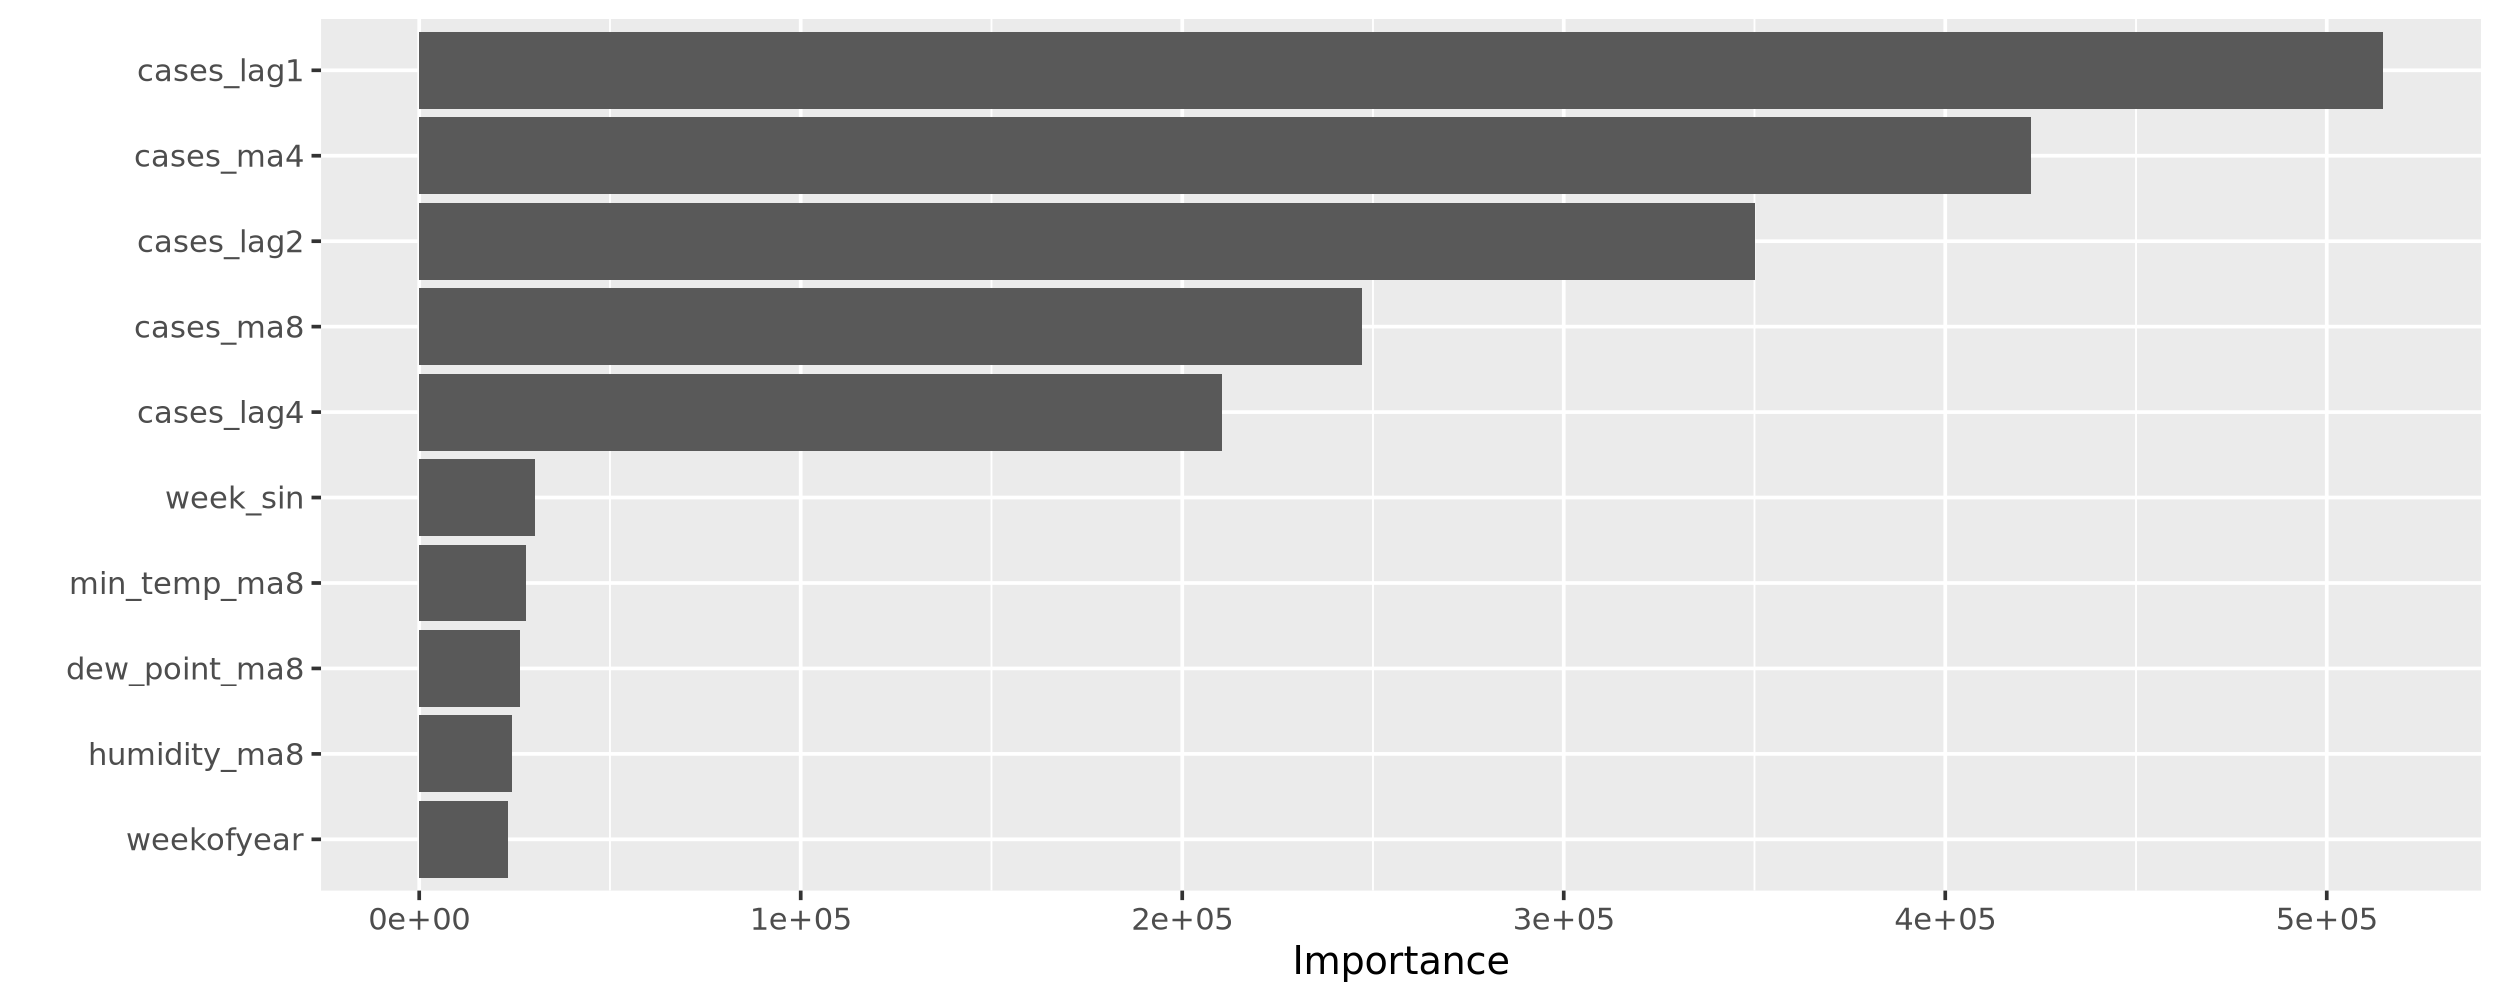

In [23]:
mod_imp = mod |> set_engine('ranger', importance = 'impurity')

mod_sj_imp_fit = mod_imp |> fit(total_cases ~ ., data = sj_lag_split$train)

vip::vip(mod_sj_imp_fit)
